# 04 · Evaluación final en test (E-06)

Este notebook usa el conjunto de **test por primera y única vez**. Los modelos ya fueron elegidos en los notebooks 02 y 03 usando validación; aquí solo se mide qué tan bien funcionan con datos nunca vistos.

Contenido:

1. Tabla final de todos los modelos seleccionados.
2. Con atajos vs. sin atajos.
3. Matrices de confusión.
4. Curvas ROC y precision-recall de los modelos de dominio.
5. Elección del umbral de decisión.
6. Análisis de errores.
7. Prueba con URLs de ejemplo escritas a mano.

In [1]:
import sys, json, os, warnings
warnings.filterwarnings("ignore")
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from tensorflow import keras
from sklearn.metrics import roc_curve, precision_recall_curve, ConfusionMatrixDisplay

RAIZ = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(RAIZ))
from src import datos, caracteristicas, texto, evaluacion

DIR_FIG, DIR_RES, DIR_MOD = RAIZ / "reports" / "figures", RAIZ / "reports" / "resultados", RAIZ / "models"
sns.set_theme(style="whitegrid")
def guardar(fig, nombre):
    fig.savefig(DIR_FIG / f"{nombre}.png", dpi=200, bbox_inches="tight")

df, train, val, test = datos.cargar_conjuntos()
y_val, y_test = val.es_phishing.values, test.es_phishing.values
print(f"test: {len(test):,} URLs ({y_test.mean():.1%} phishing)")

I0000 00:00:1795577604.992689    2028 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1795577605.837646    2028 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


test: 35,246 URLs (42.4% phishing)


## 1. Cargar los modelos seleccionados y predecir

In [2]:
seleccion = json.loads((DIR_RES / "seleccion_tabulares.json").read_text())
todas = datos.COLS_URL + datos.COLS_SOSPECHOSAS + datos.COLS_PAGINA
COLUMNAS = {"A1": todas, "A2": datos.COLS_URL + datos.COLS_PAGINA, "A3": datos.COLS_URL}

def X_tabular(d, codigo):
    return caracteristicas.variables_lexicas(d.dominio_base) if codigo == "A4" else d[COLUMNAS[codigo]]

def red(nombre_modelo, nombre_cod, f_texto):
    modelo = keras.models.load_model(DIR_MOD / nombre_modelo)
    cod = texto.CodificadorCaracteres.cargar(DIR_MOD / nombre_cod)
    return lambda d: modelo.predict(cod.transformar(f_texto(d).tolist()), batch_size=2048, verbose=0).ravel()

def tfidf(nombre, f_texto):
    modelo = joblib.load(DIR_MOD / nombre)
    return lambda d: modelo.predict_proba(f_texto(d))[:, 1]

url = lambda d: d.URL.str.lower()
norm = lambda d: datos.normalizar_url(d.URL)
dom = lambda d: d.dominio_base

# nombre -> (función que devuelve prob. de phishing, entrada, ¿usa atajos?)
PREDICTORES = {}
for esc, info in seleccion.items():
    codigo = esc.split(" ")[0]
    modelo = joblib.load(DIR_MOD / info["archivo"])
    PREDICTORES[f"{esc} · {info['modelo']}"] = (
        (lambda d, m=modelo, c=codigo: m.predict_proba(X_tabular(d, c))[:, 1]),
        "Variables tabulares", codigo != "A4")
PREDICTORES.update({
    "TF-IDF + RL · URL original": (tfidf("tfidf_url_original.joblib", url), "URL original", True),
    "CNN · URL original": (red("cnn_url_original.keras", "codificador_url_original.json", url), "URL original", True),
    "TF-IDF + RL · URL normalizada": (tfidf("tfidf_url_normalizada.joblib", norm), "URL normalizada", True),
    "TF-IDF + RL · dominio": (tfidf("tfidf_dominio.joblib", dom), "Solo dominio", False),
    "CNN · dominio": (red("cnn_dominio.keras", "codificador_dominio.json", dom), "Solo dominio", False),
    "BiGRU · dominio": (red("bigru_dominio.keras", "codificador_dominio.json", dom), "Solo dominio", False),
})

prob_val, prob_test, filas = {}, {}, []
for nombre, (predecir, entrada, atajos) in PREDICTORES.items():
    prob_val[nombre], prob_test[nombre] = predecir(val), predecir(test)
    filas.append({"modelo": nombre, "entrada": entrada, "usa_atajos": atajos,
                  **evaluacion.metricas(y_test, prob_test[nombre])})
res_test = pd.DataFrame(filas)
res_test.to_csv(DIR_RES / "test_resultados.csv", index=False)
cols = ["accuracy", "precision", "recall", "f1", "roc_auc"]
display(res_test.set_index("modelo")[["usa_atajos"] + cols + ["FN", "FP"]]
        .style.format("{:.4f}", subset=cols).background_gradient(subset=["f1"], cmap="Blues"))

E0000 00:00:1795577623.754041    2028 util.cc:131] oneDNN supports DT_BOOL only on platforms with AVX-512. Falling back to the default Eigen-based implementation if present.


,usa_atajos,accuracy,precision,recall,f1,roc_auc,FN,FP
modelo,,,,,,,,
A1 · Todas · Random Forest,True,1.0000,1.0000,1.0000,1.0000,1.0000,0,0
A2 · Sin URLSimilarityIndex · MLP,True,0.9999,0.9999,0.9999,0.9999,1.0000,1,2
A3 · Solo URL · MLP,True,0.9976,0.9999,0.9946,0.9972,0.9987,81,2
A4 · Léxicas del dominio · XGBoost (ajustado),False,0.8364,0.9213,0.6715,0.7768,0.8807,4910,857
TF-IDF + RL · URL original,True,0.9968,0.9999,0.9926,0.9962,0.9988,111,1
CNN · URL original,True,0.9978,0.9997,0.9950,0.9974,0.9985,74,4
TF-IDF + RL · URL normalizada,True,0.9014,0.9460,0.8140,0.8750,0.9427,2780,695
TF-IDF + RL · dominio,False,0.8681,0.9129,0.7616,0.8304,0.9185,3564,1086
CNN · dominio,False,0.8690,0.9520,0.7278,0.8249,0.9190,4068,549


## 2. Con atajos vs. sin atajos

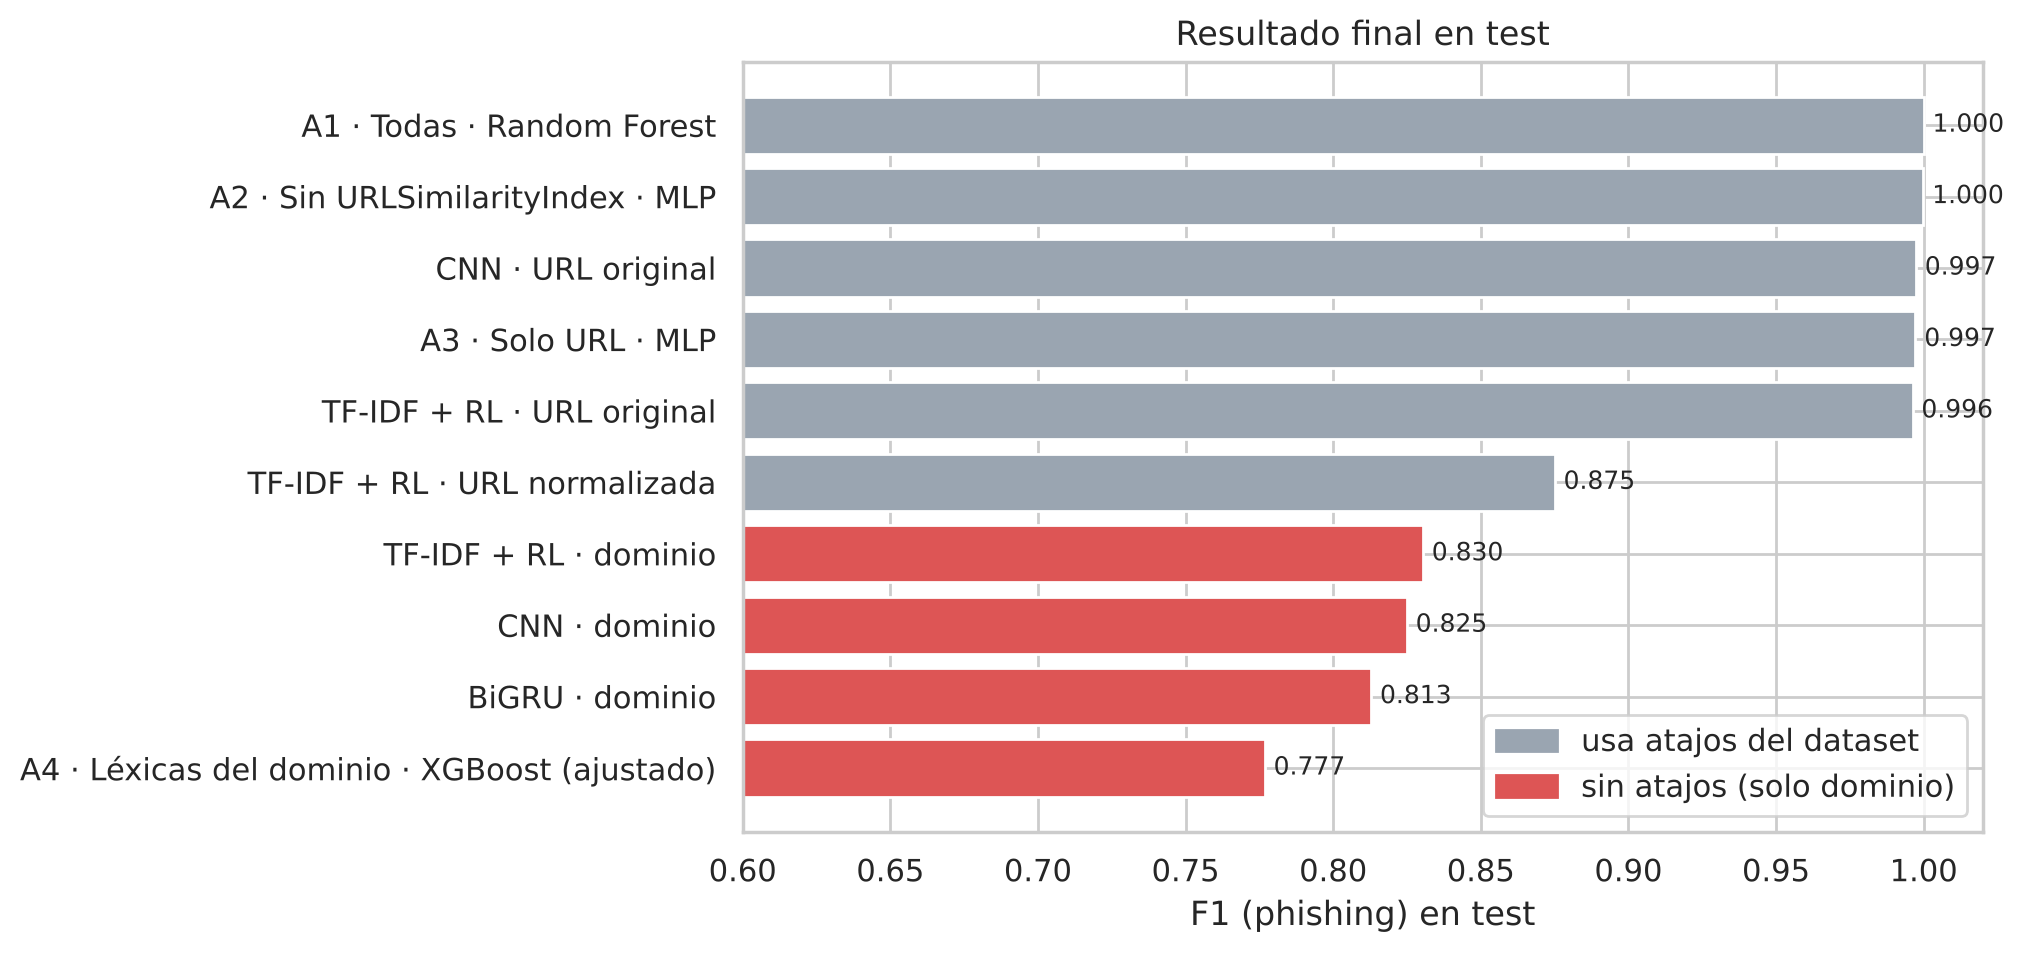

In [3]:
orden = res_test.sort_values("f1")
fig, ax = plt.subplots(figsize=(8, 5))
colores = np.where(orden.usa_atajos, "#9AA5B1", "#DD5555")
ax.barh(orden.modelo, orden.f1, color=colores)
for i, v in enumerate(orden.f1):
    ax.text(v + 0.003, i, f"{v:.3f}", va="center", fontsize=9)
ax.set_xlim(0.6, 1.02); ax.set_xlabel("F1 (phishing) en test")
ax.set_title("Resultado final en test")
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color="#9AA5B1", label="usa atajos del dataset"),
                   Patch(color="#DD5555", label="sin atajos (solo dominio)")], loc="lower right")
guardar(fig, "12_resultados_test"); plt.show()

Todo lo que usa la URL completa o las variables originales queda sobre 0,99 de F1. Los modelos que solo ven el dominio quedan bastante más abajo: esa diferencia es la que aportaban los atajos.

## 3. Matrices de confusión

Mejor con atajos: A1 · Todas · Random Forest | Mejor de dominio (según validación): CNN · dominio


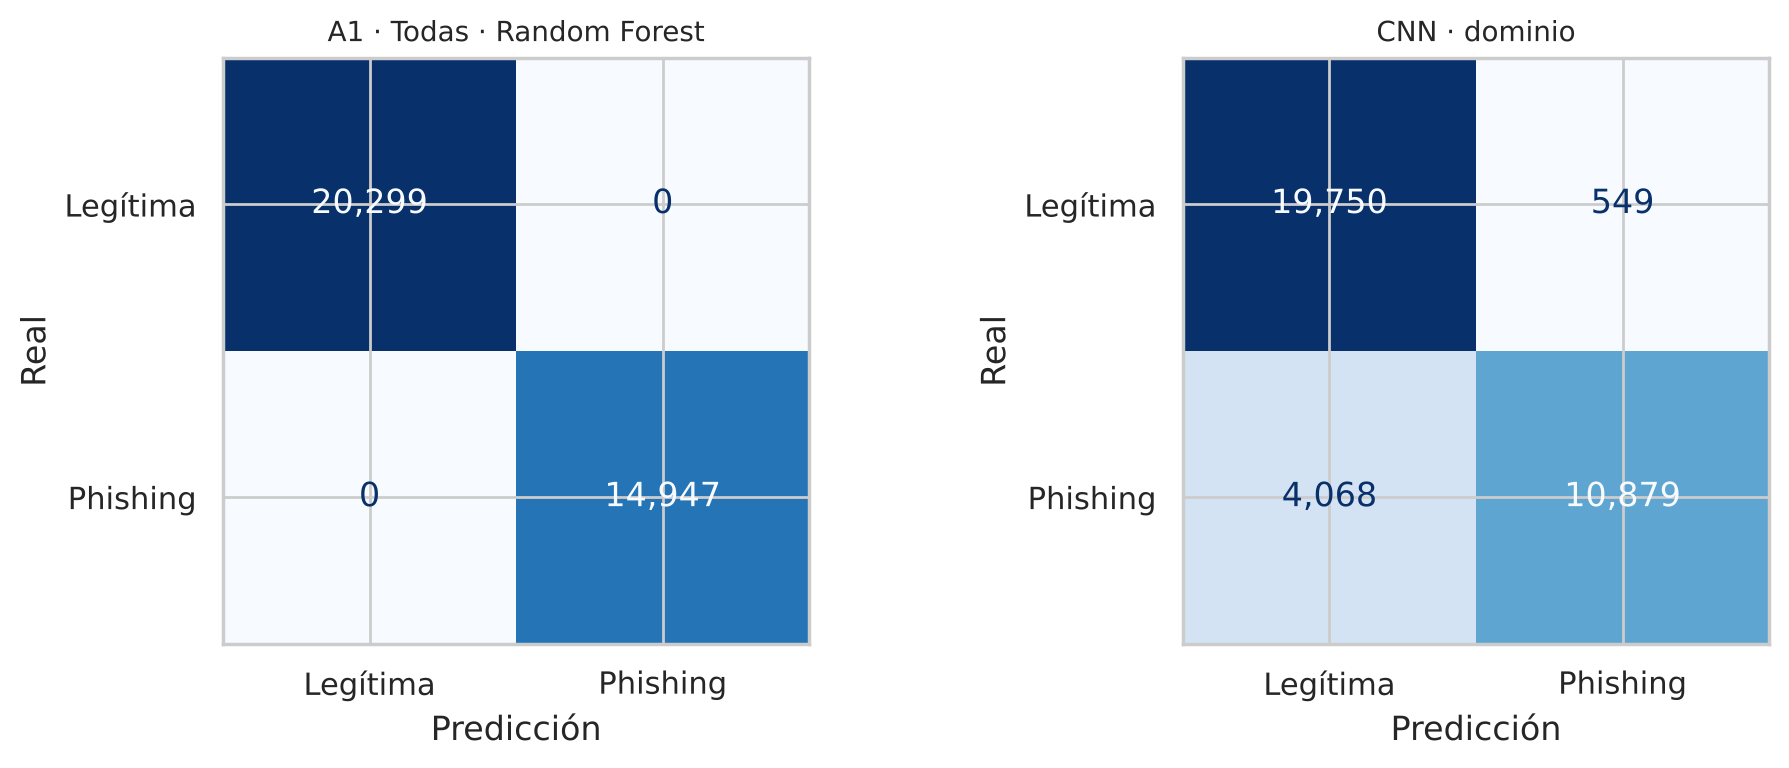

In [4]:
mejor_atajos = res_test[res_test.usa_atajos].sort_values("f1").iloc[-1].modelo
val_texto = pd.read_csv(DIR_RES / "val_texto.csv").query("entrada == 'Solo dominio'")
nombres_dom = {"TF-IDF + Reg. logística": "TF-IDF + RL · dominio", "CNN de caracteres": "CNN · dominio", "BiGRU": "BiGRU · dominio"}
MEJOR_DOM = nombres_dom[val_texto.sort_values("f1").iloc[-1].modelo]   # elegido por F1 en VALIDACIÓN
print("Mejor con atajos:", mejor_atajos, "| Mejor de dominio (según validación):", MEJOR_DOM)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, nombre in zip(axes, [mejor_atajos, MEJOR_DOM]):
    ConfusionMatrixDisplay.from_predictions(y_test, (prob_test[nombre] >= 0.5).astype(int),
        display_labels=["Legítima", "Phishing"], cmap="Blues", values_format=",", ax=ax, colorbar=False)
    ax.set_title(nombre, fontsize=10); ax.set_xlabel("Predicción"); ax.set_ylabel("Real")
fig.tight_layout(); guardar(fig, "13_matrices_confusion"); plt.show()

## 4. Curvas ROC y precision-recall (modelos que solo ven el dominio)

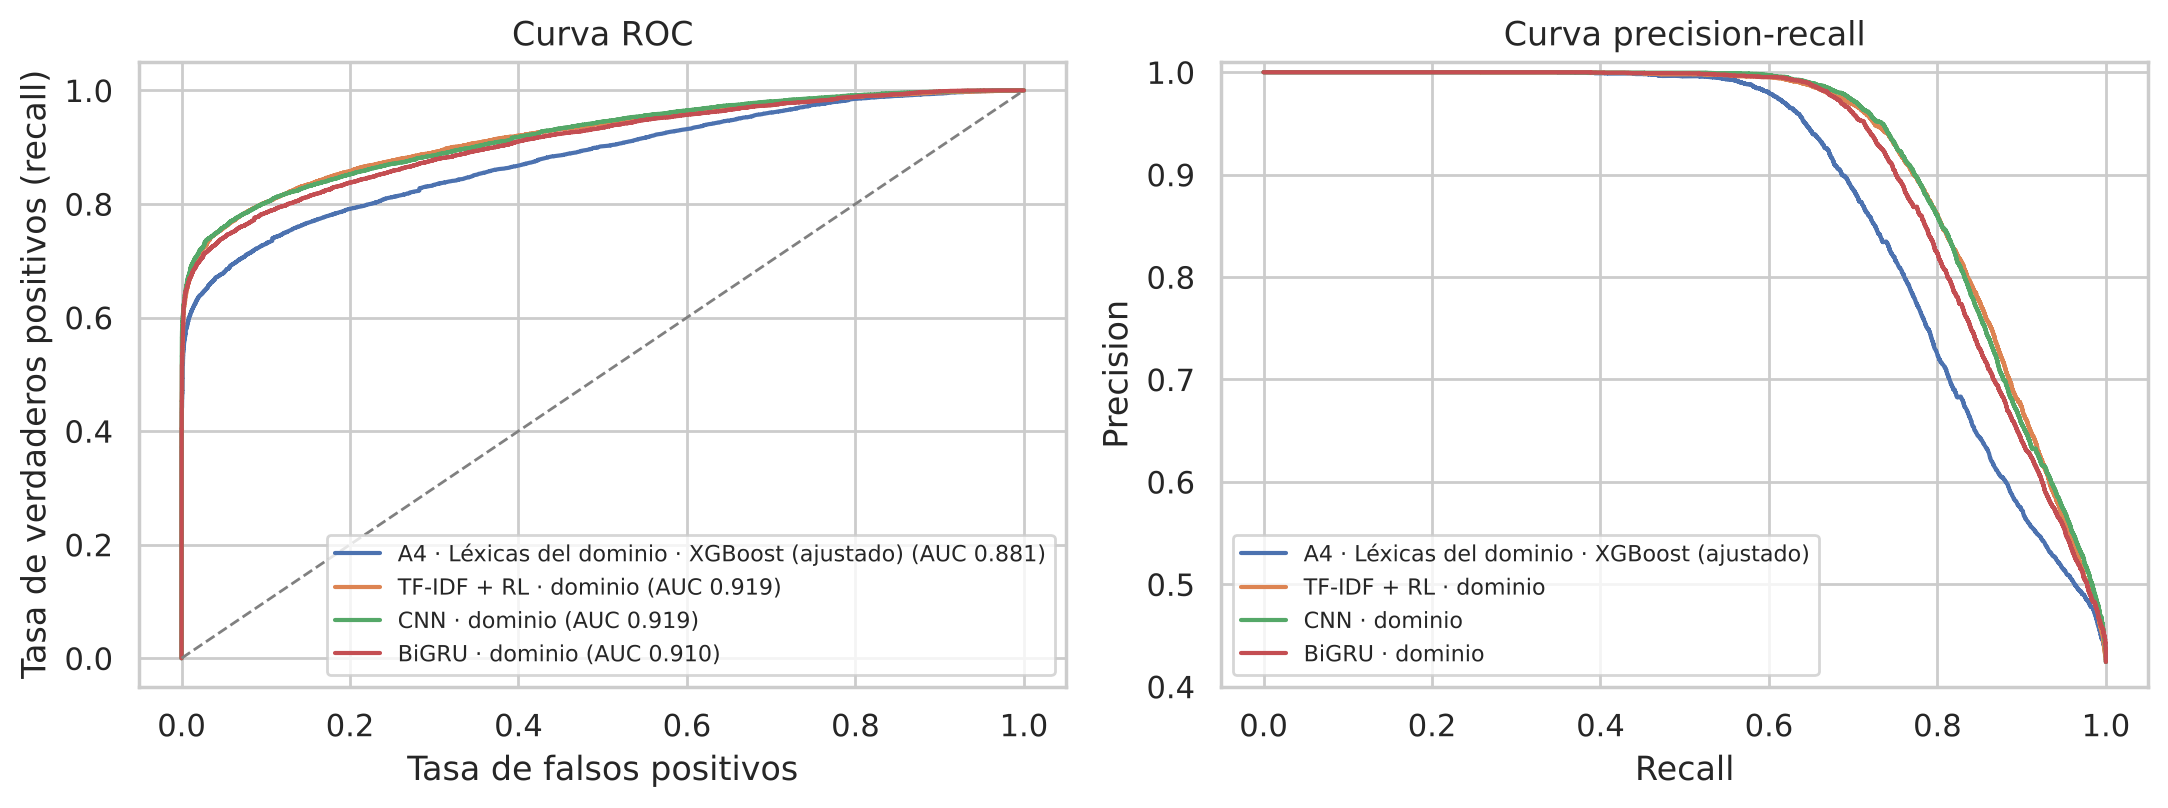

In [5]:
modelos_dom = [n for n in PREDICTORES if not PREDICTORES[n][2]]
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for nombre in modelos_dom:
    fpr, tpr, _ = roc_curve(y_test, prob_test[nombre])
    p, r, _ = precision_recall_curve(y_test, prob_test[nombre])
    auc = res_test.set_index("modelo").loc[nombre, "roc_auc"]
    axes[0].plot(fpr, tpr, label=f"{nombre} (AUC {auc:.3f})")
    axes[1].plot(r, p, label=nombre)
axes[0].plot([0, 1], [0, 1], "--", color="gray", lw=1)
axes[0].set(xlabel="Tasa de falsos positivos", ylabel="Tasa de verdaderos positivos (recall)", title="Curva ROC")
axes[1].set(xlabel="Recall", ylabel="Precision", title="Curva precision-recall", ylim=(0.4, 1.01))
axes[0].legend(fontsize=8, loc="lower right"); axes[1].legend(fontsize=8, loc="lower left")
fig.tight_layout(); guardar(fig, "14_roc_pr_dominio"); plt.show()

## 5. Elección del umbral de decisión

Por defecto una URL se marca como phishing si la probabilidad es ≥ 0,5. En seguridad suele preferirse **detectar más ataques aunque aumenten las falsas alarmas**. Elegimos en **validación** el umbral que logra al menos 90 % de recall y vemos qué pasa en test.

In [6]:
p, r, umbrales = precision_recall_curve(y_val, prob_val[MEJOR_DOM])
umbral_90 = float(umbrales[np.where(r[:-1] >= 0.90)[0][-1]])
filas_u = []
for etiqueta, u in [("0,50 (por defecto)", 0.5), (f"{umbral_90:.2f} (recall ≥ 90 % en val)", umbral_90)]:
    m = evaluacion.metricas(y_test, prob_test[MEJOR_DOM], umbral=u)
    filas_u.append({"umbral": etiqueta, **{k: m[k] for k in ["precision", "recall", "f1", "FN", "FP"]}})
tabla_umbral = pd.DataFrame(filas_u).set_index("umbral")
tabla_umbral.to_csv(DIR_RES / "umbral_mejor_dominio.csv")
display(tabla_umbral.style.format("{:.4f}", subset=["precision", "recall", "f1"]))
(DIR_RES / "modelo_demo.json").write_text(json.dumps({"modelo": MEJOR_DOM, "umbral_alto_recall": round(umbral_90, 4)}, ensure_ascii=False, indent=2))

,precision,recall,f1,FN,FP
umbral,,,,,
"0,50 (por defecto)",0.9520,0.7278,0.8249,4068,549
0.16 (recall ≥ 90 % en val),0.6687,0.8944,0.7653,1578,6624


63

Bajar el umbral detecta muchos más phishing (menos falsos negativos) a cambio de más falsas alarmas. Qué umbral usar es una **decisión de negocio**: un filtro de correo corporativo preferiría el umbral bajo; un navegador que bloquea páginas, el alto.

## 6. Análisis de errores del mejor modelo de dominio

In [7]:
errores = test.assign(prob=prob_test[MEJOR_DOM])[["dominio_base", "es_phishing", "prob"]]
fn = errores.query("es_phishing == 1 and prob < 0.5").sort_values("prob").head(12)
fp = errores.query("es_phishing == 0 and prob >= 0.5").sort_values("prob", ascending=False).head(12)
print("Falsos negativos (phishing que el modelo dejó pasar):")
display(fn)
print("Falsos positivos (legítimas marcadas como phishing):")
display(fp)

Falsos negativos (phishing que el modelo dejó pasar):


,dominio_base,es_phishing,prob
190838,tsukuru.co.jp,1,0.007848
111031,thermictechno.co.jp,1,0.010145
186963,speedlab.uk,1,0.010398
144230,amurt.org.uk,1,0.010474
198562,sporthistory.org,1,0.011529
234128,nimh.gov.vn,1,0.011854
212351,nimh.gov.vn,1,0.011854
20930,nimh.gov.vn,1,0.011854
136368,characterthelight.jp,1,0.012003
26362,locallywhitstable.co.uk,1,0.014768


Falsos positivos (legítimas marcadas como phishing):


,dominio_base,es_phishing,prob
118307,hoixuan35.website,0,0.999947
124677,doulmousi.asfalisinet.my-pro-office.gr,0,0.999918
158225,smartdnsproxy.com,0,0.999669
105551,estyn.llyw.cymru,0,0.998757
45577,bcnad.xyz,0,0.998667
225714,victor.darvariu.me,0,0.998454
11586,symplinetech.xyz,0,0.998324
122746,pawblock.dannyguo.com,0,0.995981
32065,sport.vlaanderen,0,0.995981
101676,starship.xyz,0,0.995885


In [8]:
# ¿Qué tipo de dominios de phishing se escapan? Proporción de errores según rasgos simples
errores["fn"] = (errores.es_phishing == 1) & (errores.prob < 0.5)
phish = errores[errores.es_phishing == 1].copy()
lx = caracteristicas.variables_lexicas(phish.dominio_base)
phish["termina_en_com"] = lx.tld_com == 1
phish["tiene_digitos"] = lx.n_digitos > 0
phish["largo_mayor_20"] = lx.largo > 20
resumen = pd.DataFrame({r: phish.groupby(r).fn.mean() for r in ["termina_en_com", "tiene_digitos", "largo_mayor_20"]}).T
resumen.columns = ["No", "Sí"]
print("Porcentaje de phishing NO detectado según cada rasgo:")
display((resumen * 100).round(1))

Porcentaje de phishing NO detectado según cada rasgo:


,No,Sí
termina_en_com,17.2,40.9
tiene_digitos,40.4,3.9
largo_mayor_20,43.1,8.7


Los phishing que más se escapan son los que **parecen dominios normales**: terminan en `.com`, son cortos y no tienen dígitos. Sin mirar la página ni la ruta, un dominio como `tiendaonline-ofertas.com` es difícil de distinguir de uno legítimo; ahí está el límite de este enfoque.

## 7. Prueba con URLs de ejemplo escritas a mano

Comprobamos el efecto de los atajos con URLs **que no están en el dataset**: legítimas reales **con ruta** (algo que nunca aparece entre las legítimas del dataset) y URLs de phishing **inventadas** con patrones típicos.

In [9]:
ejemplos = pd.DataFrame([
    ("https://www.google.com/maps", "Legítima"),
    ("https://es.wikipedia.org/wiki/Phishing", "Legítima"),
    ("https://github.com/54isaac09", "Legítima"),
    ("https://www.ubiobio.cl/w/", "Legítima"),
    ("https://mail.google.com/mail/u/0/", "Legítima"),
    ("http://secure-login-verify-account.xyz/signin", "Phishing (inventada)"),
    ("https://paypal-account-update.web.app/login", "Phishing (inventada)"),
    ("http://192.168.10.5/bank/login.php", "Phishing (inventada)"),
    ("https://bancoestado-cl-verificacion.top/clave", "Phishing (inventada)"),
], columns=["URL", "tipo"])
ejemplos["dominio_base"] = ejemplos.URL.map(texto.dominio_de_url)

prob_url = PREDICTORES["CNN · URL original"][0](ejemplos)
prob_dom = PREDICTORES[MEJOR_DOM][0](ejemplos)
ejemplos["P(phishing) · CNN URL original"] = prob_url.round(3)
ejemplos[f"P(phishing) · {MEJOR_DOM}"] = prob_dom.round(3)
ejemplos.drop(columns="dominio_base").to_csv(DIR_RES / "ejemplos_a_mano.csv", index=False)
ejemplos.drop(columns="dominio_base").style.format(precision=3).background_gradient(
    subset=[c for c in ejemplos.columns if c.startswith("P(")], cmap="Reds", vmin=0, vmax=1)

,URL,tipo,P(phishing) · CNN URL original,P(phishing) · CNN · dominio
0,https://www.google.com/maps,Legítima,1.000,0.527
1,https://es.wikipedia.org/wiki/Phishing,Legítima,1.000,0.592
2,https://github.com/54isaac09,Legítima,1.000,0.320
3,https://www.ubiobio.cl/w/,Legítima,1.000,0.604
4,https://mail.google.com/mail/u/0/,Legítima,1.000,0.998
5,http://secure-login-verify-account.xyz/signin,Phishing (inventada),1.000,1.000
6,https://paypal-account-update.web.app/login,Phishing (inventada),1.000,1.000
7,http://192.168.10.5/bank/login.php,Phishing (inventada),1.000,1.000
8,https://bancoestado-cl-verificacion.top/clave,Phishing (inventada),1.000,1.000


**Lectura:**

- El modelo entrenado con la **URL original** marca como phishing, con probabilidad ≈ 1,0, **todas** las URLs legítimas que tienen ruta: en el dataset ninguna legítima la tiene, así que para ese modelo "tener ruta" significa phishing. Su 99,7 % de F1 en test no se trasladaría al mundo real.
- El modelo de **dominio** no ve la ruta, así que no cae en ese error, pero tampoco es perfecto: deja a `google.com`, `es.wikipedia.org` y `ubiobio.cl` cerca del umbral y marca `mail.google.com` como phishing. La siguiente sección explica por qué.

### Sesgo residual en el dominio

Aunque quitamos el esquema, el `www.` y la ruta, el dominio todavía arrastra dos sesgos de cómo se armó el dataset:

In [10]:
d, y = df.dominio_base, df.es_phishing
# Subdominio real: más de dos etiquetas, sin contar sufijos de dos niveles como .co.uk o .com.br
sufijo_doble = d.str.contains(r"\.(?:co|com|org|net|ac|gov|edu|gob|ne|or)\.[a-z]{2}$")
tiene_subdominio = (d.str.count(r"\.") + 1 - sufijo_doble.astype(int)) > 2
print("Dominios con subdominio (además de www), % de cada clase:")
print((pd.crosstab(tiene_subdominio, y.map({0: "Legítima", 1: "Phishing"}), normalize="columns") * 100).round(1))
contiene_google = d.str.contains("google", regex=False)
print("\nDominios que contienen 'google':")
print(pd.crosstab(contiene_google, y.map({0: "Legítima", 1: "Phishing"})))
print("\nLos más comunes entre los de phishing:")
print(d[contiene_google & (y == 1)].value_counts().head(5).to_string())

Dominios con subdominio (además de www), % de cada clase:
es_phishing   Legítima  Phishing
dominio_base                    
False             96.0      45.0
True               4.0      55.0

Dominios que contienen 'google':
es_phishing   Legítima  Phishing
dominio_base                    
False           134838     99599
True                12       921

Los más comunes entre los de phishing:
dominio_base
docs.google.com                   526
sites.google.com                  180
storage.cloud.google.com           51
storage.googleapis.com             19
firebasestorage.googleapis.com     15


1. **Subdominios:** solo ~4 % de las legítimas tiene un subdominio (como `mail.` o `es.`), contra ~55 % de las de phishing. El modelo aprende que "tener subdominio" es sospechoso, y por eso falla con `mail.google.com`.
2. **Servicios legítimos usados para phishing:** hay más de 900 URLs de phishing alojadas en servicios de Google (formularios en `docs.google.com`, sitios en `sites.google.com`) y solo una docena de legítimas que contienen "google". Para el modelo, "google" se asocia a phishing.

Esto no invalida el modelo de dominio, pero muestra que **sus ~0,83 de F1 también son optimistas** para el mundo real: un dataset con URLs legítimas más variadas (con subdominios y rutas) sería necesario para una estimación confiable.

## 8. Conclusiones finales

1. **Con atajos** (variables originales o URL completa) todos los modelos logran F1 entre 0,996 y 1,000 en test; el Random Forest con todas las variables no comete ningún error en 35.246 URLs. Es lo mismo que reporta la literatura para PhiUSIIL.
2. Ese resultado **no refleja capacidad real de detección**: las legítimas siempre empiezan con `https://www.`, nunca tienen ruta y tienen `URLSimilarityIndex = 100`, y el modelo de URL original marca como phishing cualquier URL legítima con ruta.
3. **Sin atajos** (solo el dominio), el mejor resultado en test es F1 ≈ 0,83 (TF-IDF + regresión logística 0,830; CNN de caracteres 0,825; BiGRU 0,813), y todos superan a las variables léxicas hechas a mano (XGBoost, 0,777). La CNN es la más precisa (0,95) y TF-IDF la que más detecta (recall 0,76).
4. El umbral permite cambiar precision por recall: con umbral 0,16 la CNN detecta ~89 % del phishing, pero la precision baja a ~0,67.
5. **Limitaciones:** un solo dataset; las legítimas son solo páginas de inicio de sitios populares, sin subdominios ni rutas, lo que deja un sesgo residual incluso en el dominio; y el phishing alojado en servicios legítimos (`docs.google.com`, `ipfs.io`) no se puede distinguir solo por el dominio.
6. **Trabajo futuro:** validar con otra fuente de URLs (por ejemplo PhishTank y URLs legítimas con ruta y subdominios), combinar dominio y ruta en un dataset sin atajos, y explicar las predicciones de la CNN.